In [2]:
import matplotlib.pyplot as plt
import numpy as np

rng = np.random.default_rng(42)

# Subplots
Es un grafico que ocupa una posición dentro de una figura que contiene uno o varios gráficos

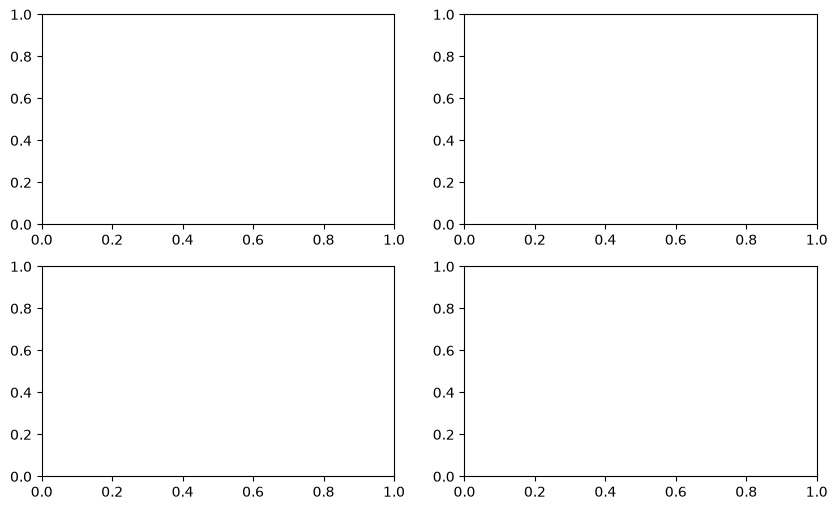

In [3]:
# (nrows, ncols)
fig, axes = plt.subplots(2,2,figsize=(10,6))
plt.show()

# Accesar axes individuales

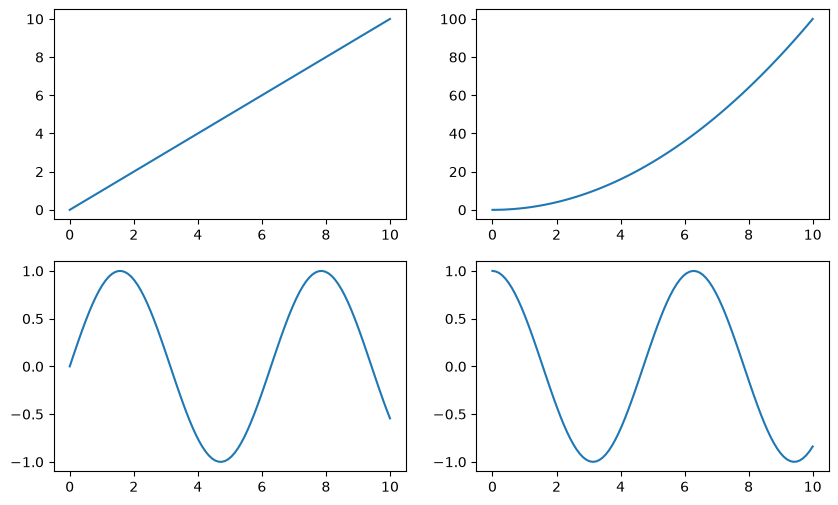

In [4]:
x = np.linspace(0,10,100)

fig, axes = plt.subplots(2,2,figsize=(10,6))

axes[0, 0].plot(x, x)
axes[0, 1].plot(x, x**2)

axes[1, 0].plot(x, np.sin(x))
axes[1, 1].plot(x, np.cos(x))

plt.show()

# Customizar cada subplot

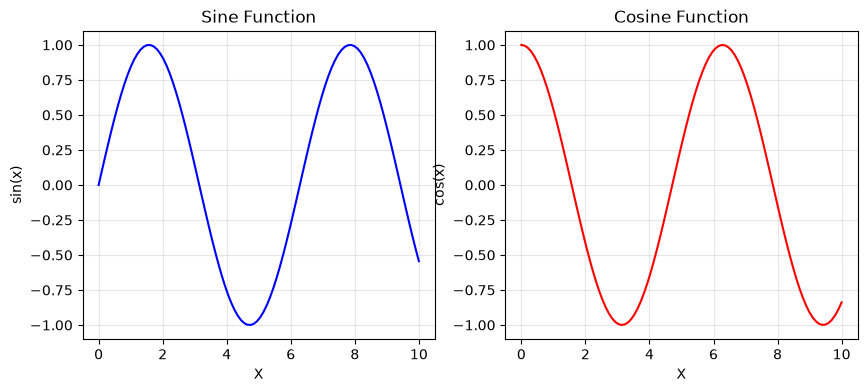

In [5]:
x = np.linspace(0, 10, 100)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

# First subplot
axes[0].plot(x, np.sin(x), color="blue")
axes[0].set_title("Sine Function")
axes[0].set_xlabel("X")
axes[0].set_ylabel("sin(x)")
axes[0].grid(alpha=0.3)

# Second subplot
axes[1].plot(x, np.cos(x), color="red")
axes[1].set_title("Cosine Function")
axes[1].set_xlabel("X")
axes[1].set_ylabel("cos(x)")
axes[1].grid(alpha=0.3)

plt.show()

# Sharing axes
Cuando varios graficos representan datos comparables, podemos compartir sus escalas

Text(0.5, 1.0, 'Training Loss')

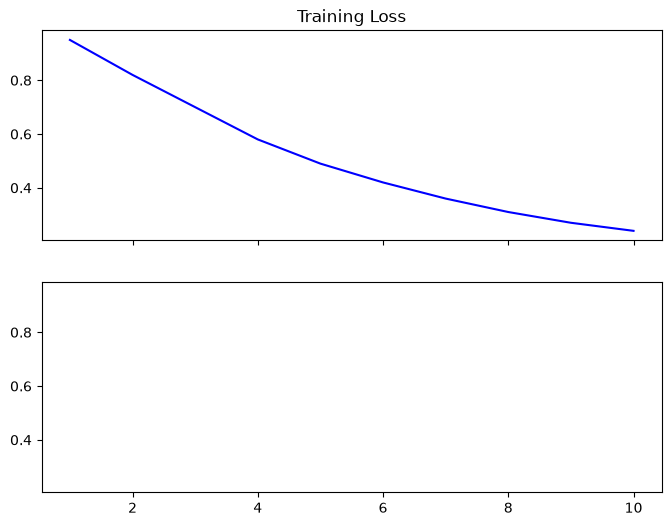

In [6]:
epochs = np.arange(1, 11)

train_loss = np.array([
    0.95, 0.82, 0.70, 0.58, 0.49,
    0.42, 0.36, 0.31, 0.27, 0.24
])

val_loss = np.array([
    1.00, 0.87, 0.76, 0.67, 0.61,
    0.59, 0.60, 0.63, 0.67, 0.72
])

fig, axes = plt.subplots(
    2, 1,
    figsize=(8, 6),
    sharex=True,
    sharey=True
)

axes[0].plot(epochs, train_loss, color="blue")
axes[0].set_title("Training Loss")

# Flattening Axes

Cuando tenemos muchos subplots, acceder a cada uno mediante ```axes[row,column]``` puede resultar incómodo.
Podemos convertir el arreglo multidimensional en uno de una sola dimensión utilizando ```flatten()```

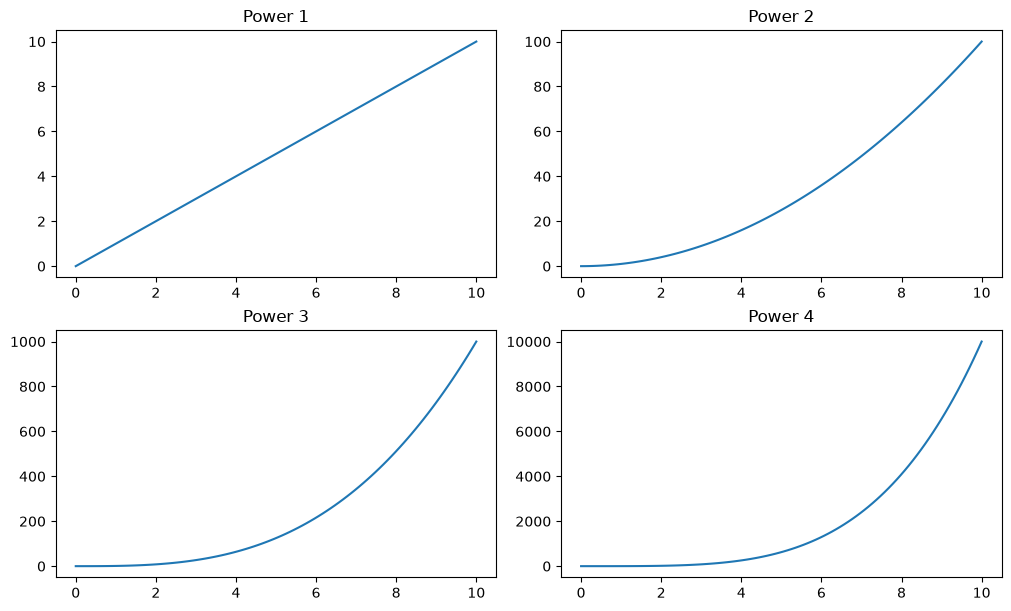

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(10, 6), constrained_layout=True)

axes = axes.flatten()

'''
Convierte axes = [
    [ax1, ax2],
    [ax3, ax4]
]
a
axes = [ax1, ax2, ax3, ax4]
'''

for i, ax in enumerate(axes):
    ax.plot(x, x ** (i + 1))
    ax.set_title(f"Power {i + 1}")

plt.show()

# Crear subplots dinamicamente

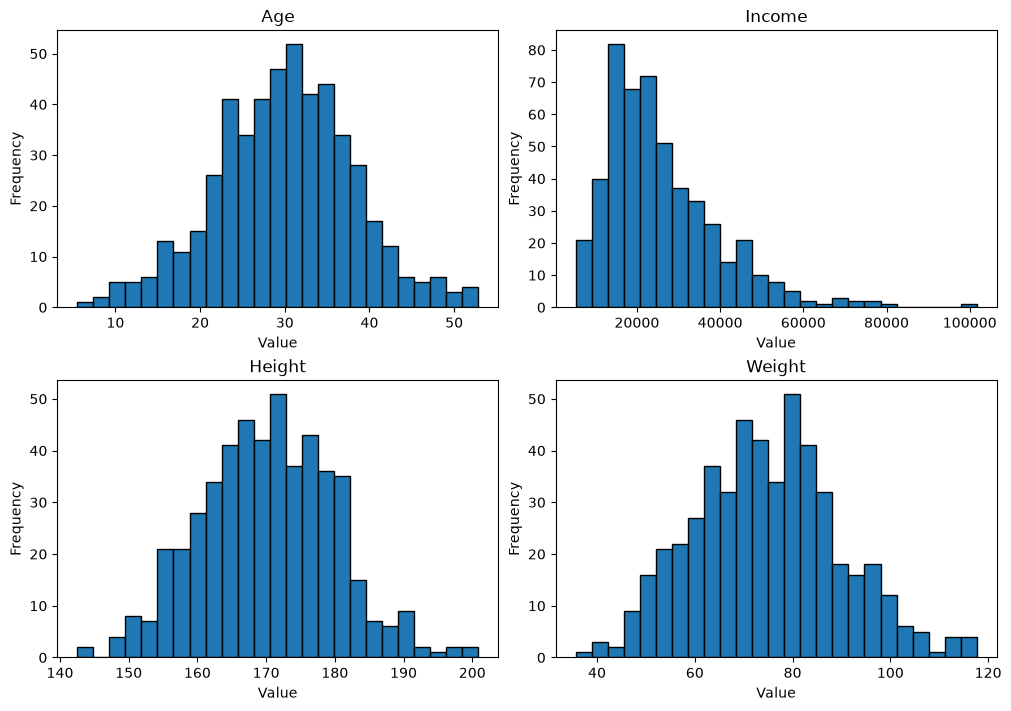

In [11]:
data = {
    "Age": rng.normal(30, 8, 500),
    "Income": rng.lognormal(10, 0.5, 500),
    "Height": rng.normal(170, 10, 500),
    "Weight": rng.normal(75, 15, 500)
}

fig, axes = plt.subplots(2,2,figsize=(10,7), constrained_layout=True)

axes = axes.flatten()

# zip permite recorrer simultaneamente los axes y las caracteristicas

for ax, (name, values) in zip(axes, data.items()):
    ax.hist(values, bins=25, edgecolor="black")
    ax.set_title(name)
    ax.set_xlabel("Value")
    ax.set_ylabel("Frequency")

plt.show()


# Figure Titles and Layout

Cuando trabajamos con multiples graficos, podemos agregar un titulo general a toda la figura

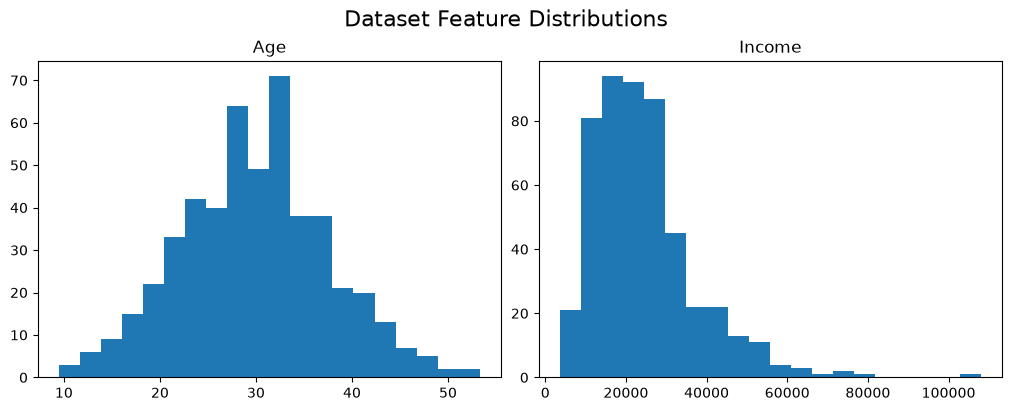

In [9]:
fig, axes = plt.subplots(
    1, 2,
    figsize=(10, 4),
    constrained_layout=True
)
# constrained_layout = fig.tight_layout(), evita que se superpongan los titulos, etiquetas y demas

axes[0].hist(data["Age"], bins=20)
axes[0].set_title("Age")

axes[1].hist(data["Income"], bins=20)
axes[1].set_title("Income")

fig.suptitle("Dataset Feature Distributions", fontsize=16)

plt.show()

---

# Ejemplo completo

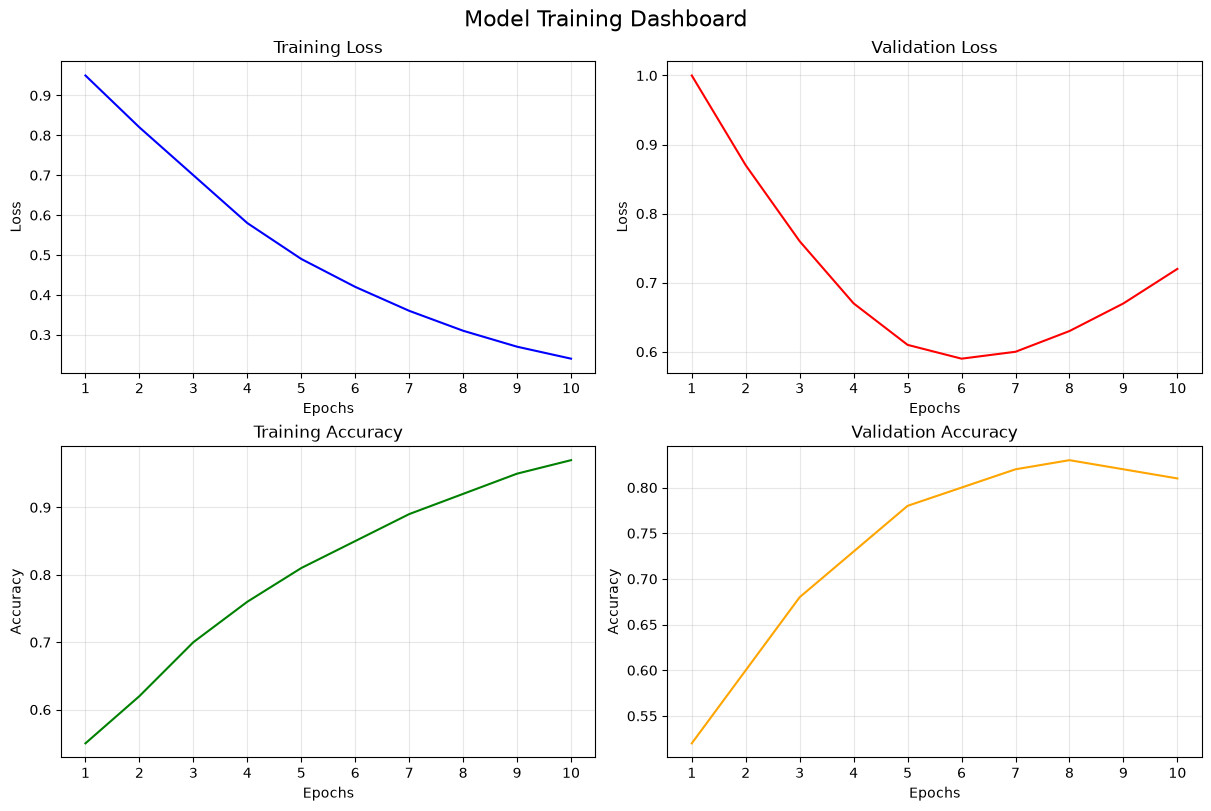

In [10]:
epochs = np.arange(1, 11)

train_loss = np.array([
    0.95, 0.82, 0.70, 0.58, 0.49,
    0.42, 0.36, 0.31, 0.27, 0.24
])

val_loss = np.array([
    1.00, 0.87, 0.76, 0.67, 0.61,
    0.59, 0.60, 0.63, 0.67, 0.72
])

train_acc = np.array([
    0.55, 0.62, 0.70, 0.76, 0.81,
    0.85, 0.89, 0.92, 0.95, 0.97
])

val_acc = np.array([
    0.52, 0.60, 0.68, 0.73, 0.78,
    0.80, 0.82, 0.83, 0.82, 0.81
])

fig, axes = plt.subplots(
    2,2,
    figsize=(12,8),
    constrained_layout=True
    )

# Training Loss
axes[0, 0].plot(epochs, train_loss, color="blue")
axes[0, 0].set_title("Training Loss")
axes[0, 0].set_ylabel("Loss")

# Validation Loss
axes[0, 1].plot(epochs, val_loss, color="red")
axes[0, 1].set_title("Validation Loss")
axes[0, 1].set_ylabel("Loss")

# Training Accuracy
axes[1, 0].plot(epochs, train_acc, color="green")
axes[1, 0].set_title("Training Accuracy")
axes[1, 0].set_ylabel("Accuracy")

# Validation Accuracy
axes[1, 1].plot(epochs, val_acc, color="orange")
axes[1, 1].set_title("Validation Accuracy")
axes[1, 1].set_ylabel("Accuracy")

for ax in axes.flat:
    ax.set_xlabel("Epochs")
    ax.set_xticks(epochs)
    ax.grid(alpha=0.3)

fig.suptitle("Model Training Dashboard", fontsize=16)

plt.show()